# Data Handling Lab: NumPy, Pandas & Matplotlib

**Goal:** practice loading, cleaning, exploring, and visualizing a small dataset.

### Open in Google Colab
1. Download this notebook from your workspace.
2. Go to [Google Colab](https://colab.research.google.com/) and choose **File → Upload notebook**.
3. Run cells from top to bottom with **Runtime → Run all** (or `Shift+Enter` cell by cell).

No external files, Kaggle account, or package installation is needed. The sample data is generated below.

## Learning objectives
- Use NumPy arrays for basic numerical calculations.
- Inspect, select, filter, sort, and summarize tabular data with Pandas.
- Handle missing values and duplicate rows.
- Create clear plots with Matplotlib.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.4.6
Pandas: 2.2.3


## 1. Create a small practice dataset
This reproducible, fictional dataset contains 24 students. We intentionally add a missing score and a duplicate so you can practice cleaning.

In [13]:
rng = np.random.default_rng(42)
n = 24

students = pd.DataFrame({
    "Student_ID": np.arange(1, n + 1),
    "Study_Hours": np.round(rng.uniform(1, 8, n), 1),
    "Attendance_Pct": rng.integers(60, 101, n),
    "Sleep_Hours": np.round(rng.uniform(5, 9, n), 1),
    "Group": np.resize(["A", "B", "C"], n),
})

# Scores are related to study time, with a little random variation.
students["Score"] = np.clip(
    np.round(45 + students["Study_Hours"] * 6 + rng.normal(0, 8, n)), 0, 100
).astype(float)
students.loc[students["Student_ID"] == 5, "Score"] = np.nan
students = pd.concat([students, students.iloc[[0]]], ignore_index=True)

students.head()

,Student_ID,Study_Hours,Attendance_Pct,Sleep_Hours,Group,Score
0,1,6.4,87,5.5,A,76.0
1,2,4.1,91,6.9,B,77.0
2,3,7.0,91,5.9,C,74.0
3,4,5.9,67,7.7,A,78.0
4,5,1.7,74,6.7,B,NaN


## 2. Inspect the data with Pandas
Try these commands when exploring a new dataset: `head`, `shape`, `info`, `dtypes`, and `describe`.

In [14]:
print("Rows and columns:", students.shape)
print("\nColumn types:\n", students.dtypes)
print("\nDataset summary:")
students.describe(include="all")

Rows and columns: (25, 6)

Column types:
 Student_ID          int64
Study_Hours       float64
Attendance_Pct      int64
Sleep_Hours       float64
Group              object
Score             float64
dtype: object

Dataset summary:


,Student_ID,Study_Hours,Attendance_Pct,Sleep_Hours,Group,Score
count,25.00000,25.00000,25.000000,25.000000,25,24.000000
unique,NaN,NaN,NaN,NaN,3,NaN
top,NaN,NaN,NaN,NaN,A,NaN
freq,NaN,NaN,NaN,NaN,9,NaN
mean,12.04000,5.26800,81.040000,6.828000,NaN,76.500000
std,7.29429,1.96187,11.182129,1.086477,NaN,11.209468
min,1.00000,1.40000,61.000000,5.000000,NaN,54.000000
25%,6.00000,4.10000,74.000000,5.800000,NaN,67.750000
50%,12.00000,5.90000,80.000000,6.800000,NaN,76.500000
75%,18.00000,6.80000,90.000000,7.800000,NaN,85.000000


In [15]:
students.info()
print("\nMissing values per column:\n", students.isna().sum())
print("\nDuplicate rows:", students.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Student_ID      25 non-null     int64  
 1   Study_Hours     25 non-null     float64
 2   Attendance_Pct  25 non-null     int64  
 3   Sleep_Hours     25 non-null     float64
 4   Group           25 non-null     object 
 5   Score           24 non-null     float64
dtypes: float64(3), int64(2), object(1)
memory usage: 1.3+ KB

Missing values per column:
 Student_ID        0
Study_Hours       0
Attendance_Pct    0
Sleep_Hours       0
Group             0
Score             1
dtype: int64

Duplicate rows: 1


## 3. NumPy practice
NumPy arrays are useful for fast numerical operations. The array below uses study hours from the dataset.

In [16]:
hours = students["Study_Hours"].to_numpy()
print("First five study-hour values:", hours[:5])
print("Mean study hours:", round(np.mean(hours), 2))
print("Maximum study hours:", np.max(hours))
print("Students studying at least 5 hours:", np.sum(hours >= 5))

First five study-hour values: [6.4 4.1 7.  5.9 1.7]
Mean study hours: 5.27
Maximum study hours: 7.8
Students studying at least 5 hours: 15


## 4. Select, filter, and sort rows
Use `.loc` for label-based selection and Boolean conditions for filtering.

In [17]:
# Select a few columns and show students with at least 6 study hours.
high_study = students.loc[
    students["Study_Hours"] >= 6,
    ["Student_ID", "Group", "Study_Hours", "Score"],
]
high_study.sort_values("Study_Hours", ascending=False).head(10)

,Student_ID,Group,Study_Hours,Score
5,6,C,7.8,96.0
22,23,B,7.8,95.0
11,12,C,7.5,88.0
23,24,C,7.3,84.0
2,3,C,7.0,74.0
13,14,B,6.8,77.0
18,19,A,6.8,82.0
7,8,B,6.5,90.0
24,1,A,6.4,76.0
0,1,A,6.4,76.0


## 5. Clean the dataset
Here we remove exact duplicate rows and fill missing scores with the median score. In a real study, choose a missing-data strategy based on what the data means.

In [18]:
clean = students.drop_duplicates().copy()
score_median = clean["Score"].median()
clean["Score"] = clean["Score"].fillna(score_median)

print("Rows before cleaning:", len(students))
print("Rows after removing duplicates:", len(clean))
print("Missing values remaining:\n", clean.isna().sum())

Rows before cleaning: 25
Rows after removing duplicates: 24
Missing values remaining:
 Student_ID        0
Study_Hours       0
Attendance_Pct    0
Sleep_Hours       0
Group             0
Score             0
dtype: int64


## 6. Add a column and summarize groups
A derived column can label students as passing (score of 60 or above). `groupby` compares results across groups.

In [19]:
clean["Passed"] = clean["Score"] >= 60
group_summary = clean.groupby("Group").agg(
    Students=("Student_ID", "count"),
    Mean_Score=("Score", "mean"),
    Mean_Study_Hours=("Study_Hours", "mean"),
    Pass_Rate=("Passed", "mean"),
).round(2)

group_summary

,Students,Mean_Score,Mean_Study_Hours,Pass_Rate
Group,,,,
A,8,73.50,5.15,1.00
B,8,80.50,5.10,1.00
C,8,75.62,5.41,0.75


## 7. Visualize with Matplotlib
Each chart has a title and labeled axes. Run each cell to display a separate plot.

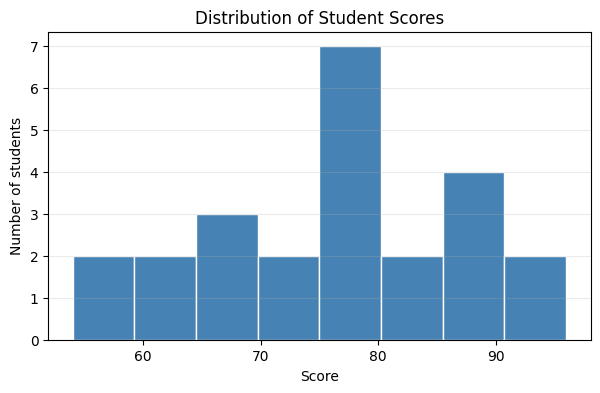

In [20]:
plt.figure(figsize=(7, 4))
plt.hist(clean["Score"], bins=8, color="steelblue", edgecolor="white")
plt.title("Distribution of Student Scores")
plt.xlabel("Score")
plt.ylabel("Number of students")
plt.grid(axis="y", alpha=0.25)
plt.show()

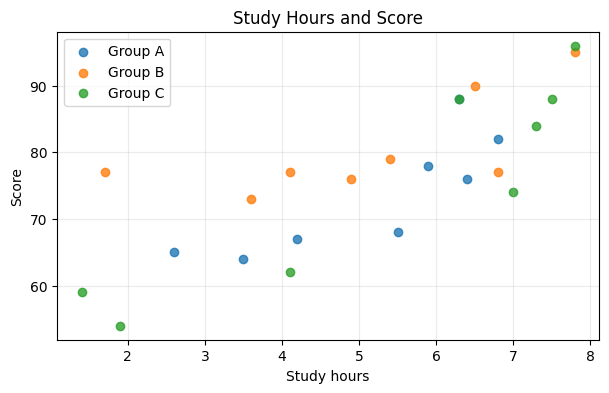

In [21]:
plt.figure(figsize=(7, 4))
for group, data in clean.groupby("Group"):
    plt.scatter(data["Study_Hours"], data["Score"], label=f"Group {group}", alpha=0.8)
plt.title("Study Hours and Score")
plt.xlabel("Study hours")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

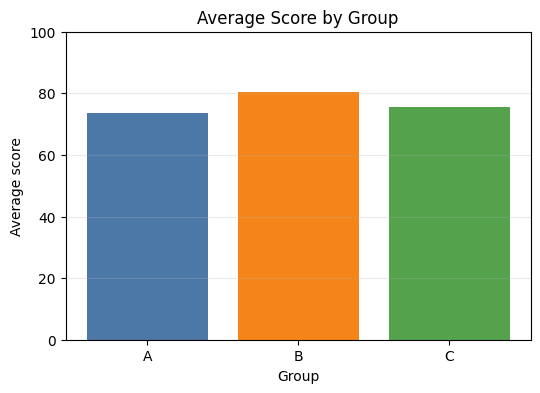

In [22]:
mean_scores = clean.groupby("Group")["Score"].mean().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(mean_scores.index, mean_scores.values, color=["#4C78A8", "#F58518", "#54A24B"])
plt.title("Average Score by Group")
plt.xlabel("Group")
plt.ylabel("Average score")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.25)
plt.show()